# 📊 Trabajo Práctico \- Análisis Exploratorio de Datos \(EDA\)

## Materia: Desarrollo de Sistemas de Inteligencia Artificial

## Grupo N° 08

### Integrantes del grupo:

Soto Ángel        1 \- Dataset: Delivery Market Argentina
Marcela Cerda  2 \- Dataset: Housing\.csv
Carla Pedrozo   3 \- Dataset: 2025 Base agregada\- Matrícula y secciones
Brian Osorio      4 \- Dataset: Videos Juegos


# PRIMERA ENTREGA

## 👉🏻 Consigna

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

## 🔍 Introducción

Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato \.csv o \.xlsx, al menos 9 columnas y 2500 filas\. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una conclusión grupal que justifica la elección del dataset con el que se continuará el desarrollo del proyecto\.

# 📁 Dataset 1 – Delivery Market Argentina \(Integrante: Soto Ángel\)

## 📝 Descripción del Dataset

Este conjunto de datos recopila información detallada sobre 3500 pedidos realizados a través de las principales aplicaciones de delivery \(PedidosYa, Rappi, UberEats, Zonakids\) en diferentes ciudades de Argentina\. Cuenta con 16 variables que incluyen segmentación de clientes \(Standard/PRO\), hábitos de consumo \(días, franjas horarias y tipos de comida\), métricas financieras \(monto del pedido, costo de envío, descuentos\), y métricas operativas \(distancias en km, tiempos de entrega en minutos y estados del pedido\)\. Su estructura permite analizar el impacto de las variables sociodemográficas y operativas en los tiempos de entrega y los costos, facilitando la identificación de ineficiencias mediante el Análisis Exploratorio de Datos\.

## Importación de Librerías

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 1\. Carga y exploración de datos

###  Carga del archivo y visualización de la estructura de datos

Se procede a cargar el archivo en formato \.csv a un DataFrame de Pandas para analizar sus dimensiones y primeros registros\.

In [2]:
df_delivery = pd.read_csv('Dataset_Market_Delivery_Argentina.csv')
print(f"El dataset contiene {df_delivery.shape[0]} filas y {df_delivery.shape[1]} columnas.")
display(df_delivery.head(10))

El dataset contiene 3500 filas y 16 columnas.


,id_pedido,app_delivery,ciudad,tipo_cliente,tipo_comida,dia_semana,franja_horaria,distancia_km,monto_pedido,aplica_promocion,descuento_aplicado,costo_envio,tiempo_entrega_minutos,metodo_pago,estado_pedido,calificacion_orden
0,PED_00001,PedidosYa,CABA,Standard,Hamburguesas,Viernes,Almuerzo,3.9,22400.0,Sí,4400.0,4500,NaN,Tarjeta_Debito,Entregado,NaN
1,PED_00002,Zonakids,Mendoza,Standard,Helado,Viernes,Almuerzo,0.9,42700.0,Sí,10900.0,3500,20.0,Efectivo,Cancelado,5.0
2,PED_00003,Rappi,Mar del Plata,PRO,Sushi,Domingo,Almuerzo,2.3,85000.0,Sí,21600.0,500,43.0,Tarjeta_Credito,Entregado,5.0
3,PED_00004,Rappi,CABA,PRO,Empanadas,Viernes,Cena,4.9,55500.0,Sí,12300.0,0,46.0,Tarjeta_Debito,Entregado,4.0
4,PED_00005,pedidos ya,La Plata,Standard,Hamburguesas,Viernes,Cena,1.2,27500.0,No,0.0,3500,25.0,MercadoPago,Entregado,5.0
5,PED_00006,PedidosYa,Córdoba,Standard,Hamburguesas,Viernes,Cena,4.4,28300.0,No,0.0,3500,43.0,MercadoPago,Entregado,NaN
6,PED_00007,PedidosYa,Mar del Plata,Standard,Árabe,Sábado,Cena,4.2,16300.0,No,0.0,3500,27.0,Tarjeta_Debito,Entregado,NaN
7,PED_00008,UberEats,Ciudad Autónoma de Buenos Aires,Standard,Árabe,Jueves,Cena,1.1,39600.0,No,0.0,4500,15.0,Efectivo,Cancelado,5.0
8,PED_00009,Rappi,Mendoza,Standard,Helado,Sábado,Cena,2.7,44800.0,No,0.0,3500,37.0,MercadoPago,Entregado,5.0
9,PED_00010,Rappi,CABA,Standard,Hamburguesas,Miércoles,Cena,2.4,45200.0,No,0.0,2500,39.0,MercadoPago,Cancelado,5.0


La ejecución confirma que el dataset posee 3500 filas y 16 columnas\. La vista preliminar \(head\) revela la presencia de variables numéricas \(como monto\_pedido y distancia\_km\) ideales para análisis distributivo, y variables categóricas \(como ciudad y app\_delivery\) aptas para análisis de frecuencia\. Además, a simple vista se detectan inconsistencias ortográficas \(como "caba" o "C\.A\.B\.A\." en la ciudad\) que requerirán limpieza\.

### Exploración de Tipos de Datos y Valores Ausentes

Se utiliza el método \.info\(\) y la suma de nulos para identificar el volumen de datos faltantes y comprender la tipología asignada a cada variable

In [3]:
print("--- Información de Columnas y Tipos de Datos ---")
df_delivery.info()

print("\n--- Conteo de Valores Ausentes (NaN) ---")
print(df_delivery.isnull().sum())

--- Información de Columnas y Tipos de Datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_pedido               3500 non-null   object 
 1   app_delivery            3500 non-null   object 
 2   ciudad                  3500 non-null   object 
 3   tipo_cliente            3500 non-null   object 
 4   tipo_comida             3500 non-null   object 
 5   dia_semana              3500 non-null   object 
 6   franja_horaria          3500 non-null   object 
 7   distancia_km            3500 non-null   float64
 8   monto_pedido            3500 non-null   float64
 9   aplica_promocion        3500 non-null   object 
 10  descuento_aplicado      3500 non-null   float64
 11  costo_envio             3500 non-null   int64  
 12  tiempo_entrega_minutos  3430 non-null   float64
 13  metodo_pago             3395 non-null   obje

El análisis revela que los tipos de datos fueron inferidos correctamente\. Se confirma la existencia de datos ausentes sistemáticos: la columna calificacion\_orden posee un 875 valores nulos, lo que equivale a un ~25% \(reflejando a los clientes que no dejan reseñas\),  y existen pequeñas proporciones de nulos \(1% al 3%\) en metodo\_pago, tiempo\_entrega\_minutos y estado\_pedido\. Este hallazgo dictamina que en la próxima etapa de análisis se deberán aplicar técnicas de imputación \(como la mediana para los tiempos\) o mantener los nulos si estos representan un comportamiento real del consumidor\.

### Análisis Estadístico Descriptivo

Se utilizarán funciones de estadística descriptiva para obtener un resumen numérico y categórico del conjunto de datos, permitiendo observar medias, desviaciones, cuartiles y frecuencias absolutas\.

In [4]:
print("--- Estadísticas de Variables Numéricas ---")
display(df_delivery.describe().round(2))

print("\n--- Estadísticas de Variables Categóricas ---")
display(df_delivery.describe(include=['object', 'category']))

--- Estadísticas de Variables Numéricas ---


,distancia_km,monto_pedido,descuento_aplicado,costo_envio,tiempo_entrega_minutos,calificacion_orden
count,3500.00,3500.00,3500.00,3500.00,3430.00,2625.00
mean,2.97,37893.23,3080.83,2669.86,31.82,4.15
std,4.21,18217.03,4581.91,1822.56,16.00,1.12
min,0.30,15000.00,0.00,0.00,15.00,1.00
25%,1.50,22700.00,0.00,500.00,23.00,4.00
50%,2.20,35800.00,0.00,3500.00,30.00,5.00
75%,3.40,49300.00,5600.00,3500.00,37.00,5.00
max,59.30,115100.00,33100.00,6000.00,180.00,5.00



--- Estadísticas de Variables Categóricas ---


,id_pedido,app_delivery,ciudad,tipo_cliente,tipo_comida,dia_semana,franja_horaria,aplica_promocion,metodo_pago,estado_pedido
count,3500,3500,3500,3500,3500,3500,3500,3500,3395,3465
unique,3500,10,14,2,7,7,4,2,4,3
top,PED_00001,PedidosYa,CABA,Standard,Árabe,Sábado,Cena,No,MercadoPago,Entregado
freq,1,1173,1170,2521,553,754,1778,2053,1337,3048


En las variables numéricas, se detecta un potencial valor atípico en distancia\_km, ya que el valor máximo es excesivamente alto \(cercano a 60 km\) en comparación con el percentil 75%, lo que empuja el tiempo\_entrega\_minutos hasta los 180 minutos\. En las variables categóricas, observamos que el valor más frecuente \(top\) en franja\_horaria es la "Cena", y descubrimos que la cantidad de valores únicos \(unique\) en columnas como ciudad o app\_delivery es mayor a la esperada, lo que sugiere errores de tipeo\.

### Detección de Errores de Codificación e Inconsistencias

Se inspeccionarán los valores únicos de las principales variables categóricas para corroborar si existen problemas de estandarización o de ingreso de datos\.

In [5]:
print("Valores únicos en la columna 'ciudad':")
print(df_delivery['ciudad'].unique())

print("\nValores únicos en la columna 'app_delivery':")
print(df_delivery['app_delivery'].unique())

print("\nConteo de métodos de pago:")
print(df_delivery['metodo_pago'].value_counts())

Valores únicos en la columna 'ciudad':
['CABA' 'Mendoza' 'Mar del Plata' 'La Plata' 'Córdoba'
 'Ciudad Autónoma de Buenos Aires' 'C.A.B.A.' 'caba' 'rosario' 'cordoba'
 'Rosario' 'ROSARIO' 'Cordoba' 'Cba']

Valores únicos en la columna 'app_delivery':
['PedidosYa' 'Zonakids' 'Rappi' 'pedidos ya' 'UberEats' 'Pedidos Ya'
 'RAPPI' 'PeYa' 'rapi' 'rappi']

Conteo de métodos de pago:
metodo_pago
MercadoPago        1337
Tarjeta_Credito    1024
Tarjeta_Debito      524
Efectivo            510
Name: count, dtype: int64


La exploración revela múltiples inconsistencias de formato\. En la ciudad encontramos registros duplicados conceptualmente por uso de mayúsculas, minúsculas y/o abreviaturas \(ej\. "CABA", "caba", "Ciudad Autónoma de Buenos Aires"\)\. Lo mismo ocurre en app\_delivery \(ej\. "PeYa", "pedidos ya", "PedidosYa"\) y en metodo\_pago\. Esto confirma la necesidad obligatoria de aplicar una etapa de limpieza y estandarización utilizando diccionarios de reemplazo y funciones de homogeneización de texto antes de generar visualizaciones\.

## 2\. Visualizaciones y análisis

### Gráfico 1: Cantidad de pedidos por App \(Countplot\)

Este gráfico nos mostrará cuántos pedidos se hicieron en cada aplicación de delivery\.

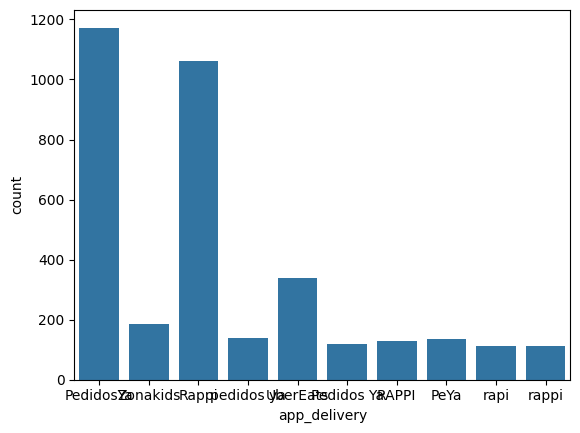

In [6]:
sns.countplot(x="app_delivery", data=df_delivery)
plt.show()

📌 Al no estar los datos limpios, se encuentra una inconsistencia en la información por lo que no es posible distinguir la aplicación de delivery más utilizada\.

### Gráfico 2: Relación entre la distancia y el monto del pedido \(Scatterplot\)

Se usa un diagrama de dispersión para ver si existe alguna relación entre los kilómetros de distancia del envío y el monto total del pedido\. Además, se colorean los puntos según la app

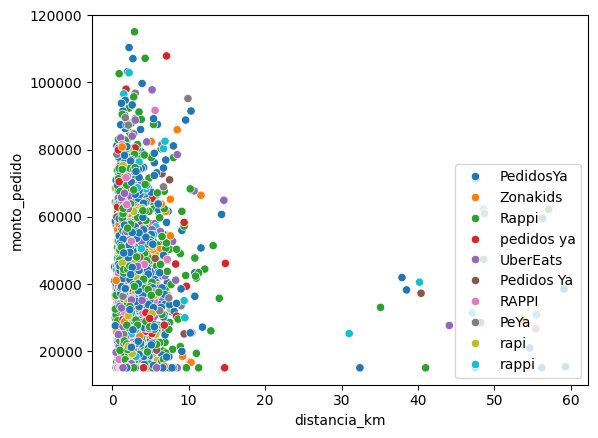

In [7]:
sns.scatterplot(x="distancia_km", y="monto_pedido", data=df_delivery, hue="app_delivery")
plt.legend(loc='lower right')
plt.show()

Aquí se pueden observar si los puntos suben a medida que se mueven a la derecha, y si se ve alguna app que destaque con los pedidos más costosos\.

## 3\. Observaciones generales

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

Entre los patrones observados, se destaca un fuerte dominio en el mercado por parte de dos aplicaciones principales \(PedidosYa y Rappi\), las cuales concentran más del 60% de los pedidos\. En cuanto a las preferencias gastronómicas, el consumo está muy distribuido, liderando levemente la comida Árabe, seguida muy de cerca por clásicos como Pizza, Helado y Hamburguesas\. Además, se observa que el tiempo medio de entrega ronda los 30 minutos, con un gasto promedio por pedido cercano a los $37\.800 pesos\.

En cuanto a la calidad de los datos, el dataset presenta un buen volumen de información\. Sin embargo, la calidad se ve afectada por la presencia de valores nulos\. El caso más crítico es la columna calificacion\_orden, a la cual le faltan 875 registros\. También hay faltantes menores en metodo\_pago, tiempo\_entrega\_minutos y estado\_pedido\. Adicionalmente, se detectó una falta de estandarización en app\_delivery, donde "PedidosYa" y "pedidos ya" están ingresados como valores distintos y requerirán limpieza\.

Por último y no menos importante, las variables como monto\_pedido, tiempo\_entrega\_minutos y ciudad resultan las más interesantes para segmentar el negocio\. La estructura de estos datos abre la puerta a análisis más complejos en próximas etapas: por ejemplo, la aplicación de mapas de calor \(heatmaps\) para detectar correlaciones fuertes \(ej\. distancia vs\. costo de envío\), el uso de histogramas \(histplots\) para entender a fondo la distribución de los tiempos de entrega, y gráficos de barras agrupados para evaluar cómo varía la facturación según el día de la semana\.

# 📁 Dataset 2 – Housing\.csv  \- Integrante: Marcela Cerda

##  📝 Descripción del Dataset

Este conjunto de datos recopila información de  2725 propiedades  y 13 columnas con  los siguientes datos: precio, superficie, habientes, baños, estacionamiento, aire acondicionado , habitación de invitados etc\.

## Importación de Librerías

In [7]:
#Importación de librerías
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## 1\. Carga y exploración de datos

### Nombre de la acción

Interpretación de la acción

In [9]:
#Código para cargar el dataset y mostrar estructura
dt = pd.read_csv('Housing.csv')

### Código para analizar el dataset y mostrar estructura

Método shape para el dataset precargado de seaborn

In [10]:
dt.shape

(2725, 13)

## Código para mostrar los tipos de datos

In [11]:
dt.dtypes

price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object

## Funcion Head

Muestra las primeras n filas del DataFrame \(por defecto n=5\)\. Es útil para revisar cómo se ven las columnas y los primeros registros cargados\.

In [12]:
dt.head(20)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


## Funcion Tail

Muestra las últimas n filas del DataFrame \(por defecto n=5\)\. Se suele usar para verificar si los datos al final se cargaron correctamente o para revisar registros recientes en series temporales\.

In [13]:
dt.tail(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
2715,2100000,3360,2,1,1,yes,no,no,no,no,1,no,unfurnished
2716,1960000,3420,5,1,2,no,no,no,no,no,0,no,unfurnished
2717,1890000,1700,3,1,2,yes,no,no,no,no,0,no,unfurnished
2718,1890000,3649,2,1,1,yes,no,no,no,no,0,no,unfurnished
2719,1855000,2990,2,1,1,no,no,no,no,no,1,no,unfurnished
2720,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
2721,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
2722,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
2723,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
2724,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


## Descripción general del conjunto de datos

Podemos obtener una descripción general del conjunto de datos utilizando la función describe de pandas:

\.describe\(\) genera estadísticas descriptivas de las columnas numéricas por defecto:

In [14]:
dt.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,2.725000e+03,2725.000000,2725.000000,2725.000000,2725.000000,2725.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.869066e+06,2168.547088,0.737522,0.502101,0.866855,0.860953
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


## Función \.describe\(\)\.T

El \.T significa transpose, o sea, gira la tabla:

In [15]:
dt.describe().T


,count,mean,std,min,25%,50%,75%,max
price,2725.0,4.766729e+06,1.869066e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,2725.0,5.150541e+03,2.168547e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,2725.0,2.965138e+00,7.375218e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,2725.0,1.286239e+00,5.021006e-01,1.0,1.0,1.0,2.0,4.0
stories,2725.0,1.805505e+00,8.668553e-01,1.0,1.0,2.0,2.0,4.0
parking,2725.0,6.935780e-01,8.609529e-01,0.0,0.0,0.0,1.0,3.0


## Función describe \(include=\['category'\]\)

In [16]:
#dt.describe(include=['category'])  
#no hay datos categoricos

## Función describe\(include="all"\)\.transpose\(\)

Como mezcla tipos de datos, cada columna tendrá distintas métricas \(numéricas o categóricas\)\.

In [17]:
dt.describe(include="all").transpose()


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,2725.0,NaN,NaN,NaN,4766729.247706,1869065.807455,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,2725.0,NaN,NaN,NaN,5150.541284,2168.547088,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,2725.0,NaN,NaN,NaN,2.965138,0.737522,1.0,2.0,3.0,3.0,6.0
bathrooms,2725.0,NaN,NaN,NaN,1.286239,0.502101,1.0,1.0,1.0,2.0,4.0
stories,2725.0,NaN,NaN,NaN,1.805505,0.866855,1.0,1.0,2.0,2.0,4.0
mainroad,2725,2,yes,2340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,2725,2,no,2240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,2725,2,no,1770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,2725,2,no,2600,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airconditioning,2725,2,no,1865,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Información de las columnas

Podemos obtener información sobre las columnas en el conjunto de datos utilizando la función \`info\` de pandas:

In [18]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2725 entries, 0 to 2724
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             2725 non-null   int64 
 1   area              2725 non-null   int64 
 2   bedrooms          2725 non-null   int64 
 3   bathrooms         2725 non-null   int64 
 4   stories           2725 non-null   int64 
 5   mainroad          2725 non-null   object
 6   guestroom         2725 non-null   object
 7   basement          2725 non-null   object
 8   hotwaterheating   2725 non-null   object
 9   airconditioning   2725 non-null   object
 10  parking           2725 non-null   int64 
 11  prefarea          2725 non-null   object
 12  furnishingstatus  2725 non-null   object
dtypes: int64(6), object(7)
memory usage: 276.9+ KB


### Método \.isnull\(\)

Esto nos dará información sobre el número de valores no nulos en cada columna y el tipo de datos de cada columna\.

In [19]:
dt.isnull()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2720,False,False,False,False,False,False,False,False,False,False,False,False,False
2721,False,False,False,False,False,False,False,False,False,False,False,False,False
2722,False,False,False,False,False,False,False,False,False,False,False,False,False
2723,False,False,False,False,False,False,False,False,False,False,False,False,False


### \.isnull\(\)\.sum\(\)

In [20]:
dt.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

## 2\. Visualizaciones y análisis

###  Función scatterplot \- Diagrama de dispersión

Una forma común de visualizar la relación entre dos variables numéricas es mediante un diagrama de dispersión\. Seaborn hace que sea fácil crear un diagrama de dispersión utilizando la función scatterplot:

## Gráfico 1

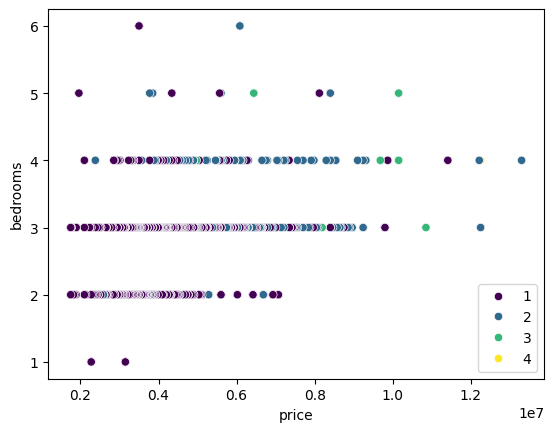

In [21]:
import matplotlib.pyplot as plt
sns.scatterplot(x="price", y="bedrooms", data=dt, hue='bathrooms', palette='viridis')
plt.legend(loc='lower right')

## Gráfico 2

###  Función Pairplot

Una forma común de visualizar la relación entre dos variables numéricas es mediante un diagrama de dispersión\. Seaborn hace que sea fácil crear un diagrama de dispersión utilizando la función scatterplot:

Uso: Exploración rápida de relaciones múltiples y distribución marginal

/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When 

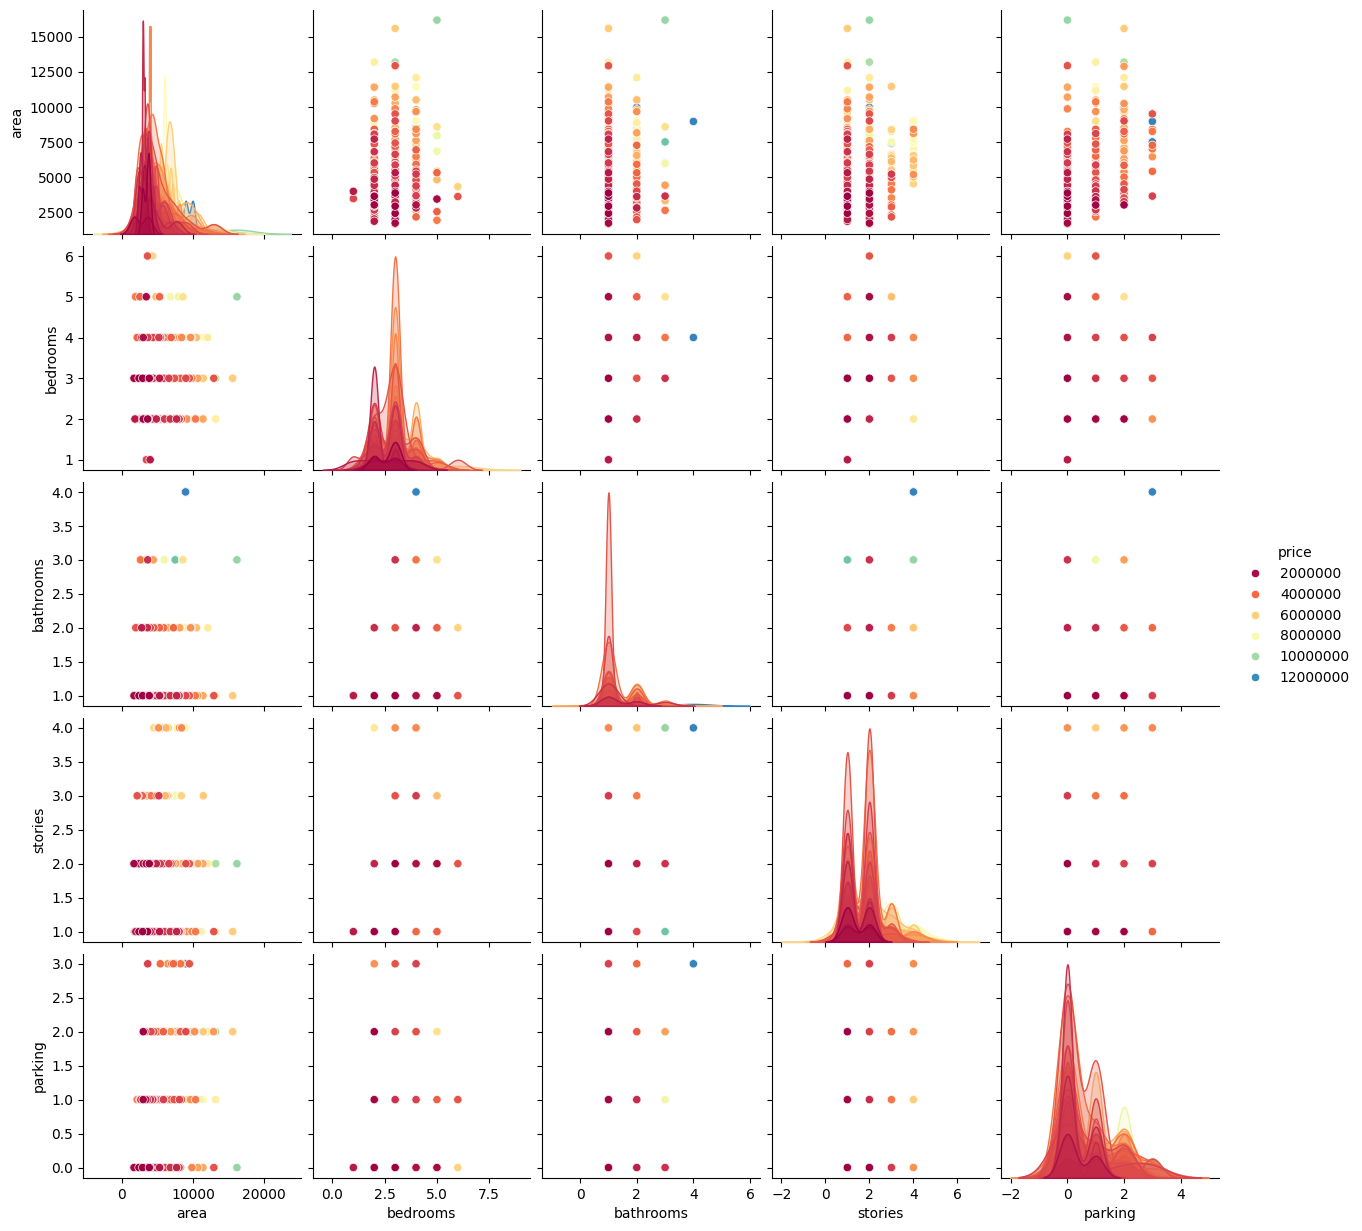

In [11]:
sns.pairplot(dt, hue='price', palette='Spectral') #, hue='area',')

Esto nos dará un diagrama de dispersión de la relación entre el precio y los m2 y ambientes, y los baños \. Podemos ver que hay una relación positiva entre ambas variables, lo que significa que a medida que aumenta el precio, también lo hace los ambientes, baños y m2\.

## Grafico 3

### Función barplot \- Diagrama de barras

\- Qué muestra: Comparación de promedios o sumas de una variable numérica según categorías\.

\- Uso: Comparar valores medios por grupo\.

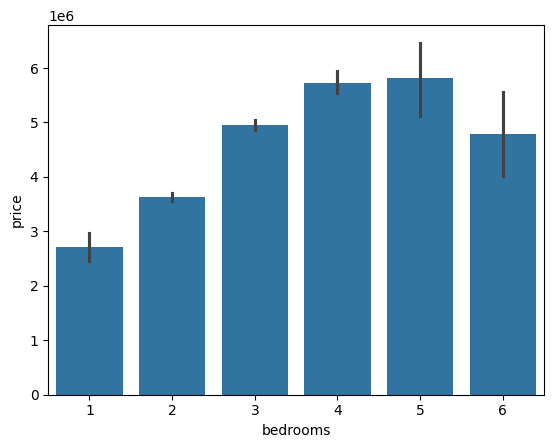

In [33]:
sns.barplot( x="bedrooms", y="price", data=dt) #, hue='sex', palette='viridis')
plt.show()

Esto nos dará un diagrama de barras de la distribución de la variable "bedrooms" en el conjunto de datos\. Podemos ver que el precio mas alto de las propiedades es por 4 y 5 habitaciones

## Grafico 4

### Función histplot \- Histograma


\- Qué muestra: Distribución de frecuencia de una variable numérica\.

<Axes: xlabel='price', ylabel='Count'>

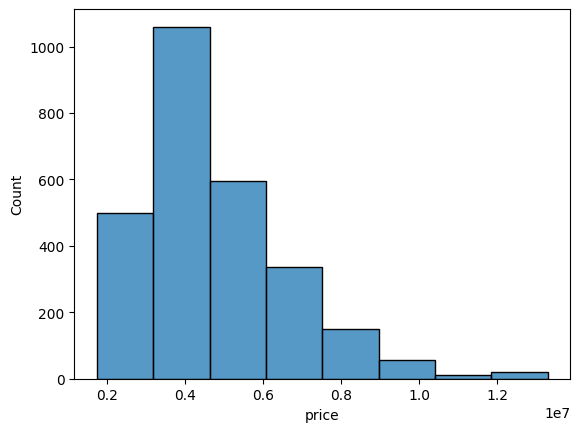

In [35]:
sns.histplot(x="price", bins = 8, data=dt)

Esto nos dará un histograma de la distribución del precio de los inmebles  en el conjunto de datos\. Podemos ver que la mayoría de las observaciones se encuentran entre $0\.4 y $0\.6

# 📁 Dataset 3 – 2025 Base agregada\- Matrícula y secciones
Integrante: Carla Pedrozo

## 📝 Descripción del Dataset

Dataset del Ministerio de Educación 2025\.Las bases de datos incluyen información sistematizada de las principales variables de matrícula y provincias\. La información se encuentra clasificada por sector de gestión \(estatal/privado\), ámbito\(urbano/rural\), entre otras\. 

## Importación de Librerías

In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


## 1\. Carga y exploración de datos

###  Conversión a DataFrame

Convertimos el dataset matricula\.xlsx en un DataFrame para poder trabajarlo con posterioridad con la librería pandas\.

In [46]:
df = pd.read_excel('matricula.xlsx')
df = df.iloc[:, 0:9]
df.head()

,provincia,departamento,sector,ambito,lactantes,deambulantes,s2,s3,s4
0,Buenos Aires,25 DE MAYO,Estatal,Rural,,,35,57,57
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,29,109,267,243,316
2,Buenos Aires,25 DE MAYO,Privado,Urbano,,,,103,105
3,Buenos Aires,9 DE JULIO,Estatal,Rural,,,57,67,75
4,Buenos Aires,9 DE JULIO,Estatal,Urbano,,,206,298,307


Se transforma el archivo en DataFrame para trabajar con la librería pandas\. Se recortan las columnas a las primeras 9 para ajustarse a la consigna\. Con head\(\) se comprueba que los datos cargaron correctamente, identificando variables categóricas como provincia, departamento, sector y ámbito\.

###   Análisis

Se aplica info\(\) para ver la cantidad de filas, columnas, tipos de datos y uso de memoria\.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217 entries, 0 to 1216
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   provincia     1217 non-null   object
 1   departamento  1217 non-null   object
 2   sector        1217 non-null   object
 3   ambito        1217 non-null   object
 4   lactantes     1217 non-null   object
 5   deambulantes  1217 non-null   object
 6   s2            1217 non-null   object
 7   s3            1217 non-null   object
 8   s4            1217 non-null   object
dtypes: object(9)
memory usage: 85.7+ KB


Se observa que tiene 1217 filas \(de 0a 1216\) y 9 columnas \(de provincia a multinivel\), todas de tipo texto \(object\)\.El uso de moria es de 85\.7\+ KB\. Tiene muchos valores vacíos en lactantes y deambulantes porque no todos los establecimientos ofrecen esas salas\.

In [48]:
df = df.replace(r'^\s*$', np.nan, regex=True)
cols_numericas = ['lactantes', 'deambulantes', 's2', 's3', 's4']
for col in cols_numericas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217 entries, 0 to 1216
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   provincia     1217 non-null   object 
 1   departamento  1217 non-null   object 
 2   sector        1217 non-null   object 
 3   ambito        1217 non-null   object 
 4   lactantes     248 non-null    float64
 5   deambulantes  341 non-null    float64
 6   s2            601 non-null    float64
 7   s3            1141 non-null   float64
 8   s4            1198 non-null   float64
dtypes: float64(5), object(4)
memory usage: 85.7+ KB
/tmp/ipykernel_1224/3452776557.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(r'^\s*$', np.nan, regex=True)


In [50]:
df.describe(include="all")

,provincia,departamento,sector,ambito,lactantes,deambulantes,s2,s3,s4
count,1217,1217,1217,1217,248.000000,341.000000,601.000000,1141.000000,1198.000000
unique,24,436,2,2,NaN,NaN,NaN,NaN,NaN
top,Buenos Aires,Enmascarado,Estatal,Urbano,NaN,NaN,NaN,NaN,NaN
freq,325,68,901,714,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,20.314516,58.826979,146.392679,266.932515,414.918197
std,NaN,NaN,NaN,NaN,23.938473,78.741588,224.109316,579.574298,820.866278
min,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,1.000000
25%,NaN,NaN,NaN,NaN,5.000000,10.000000,21.000000,31.000000,59.000000
50%,NaN,NaN,NaN,NaN,11.000000,28.000000,57.000000,81.000000,150.500000
75%,NaN,NaN,NaN,NaN,26.000000,75.000000,173.000000,233.000000,393.000000


## 

In [52]:
df.isnull().sum()


provincia         0
departamento      0
sector            0
ambito            0
lactantes       969
deambulantes    876
s2              616
s3               76
s4               19
dtype: int64

## 2\. Visualizaciones y análisis

###  \[Nombre del gráfico\]

Distribución de establecimientos por ámbito

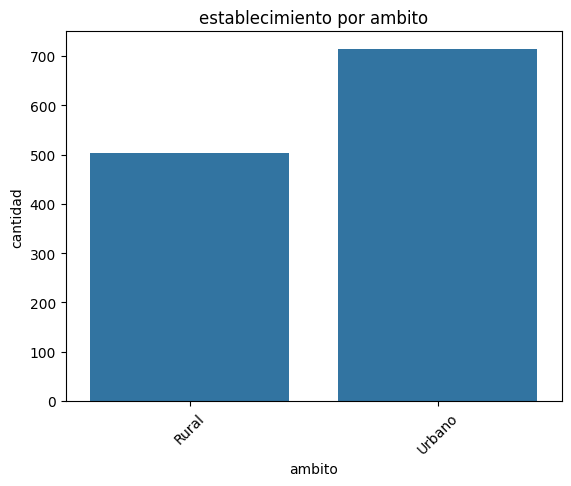

In [13]:
sns.countplot(data=df, x='ambito')
plt.title('establecimiento por ambito')
plt.xlabel('ambito')
plt.ylabel('cantidad')
plt.xticks(rotation=45)
plt.show()

Se observa que la mayoría de los establecimientos son de ámbito urbano frente al rural\. Esto indica que la oferta de nivel inicial se concentra en zonas urbanas\.

###  \[Nombre del gráfico\]

 Top 8 provincias por sector de gestión

/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


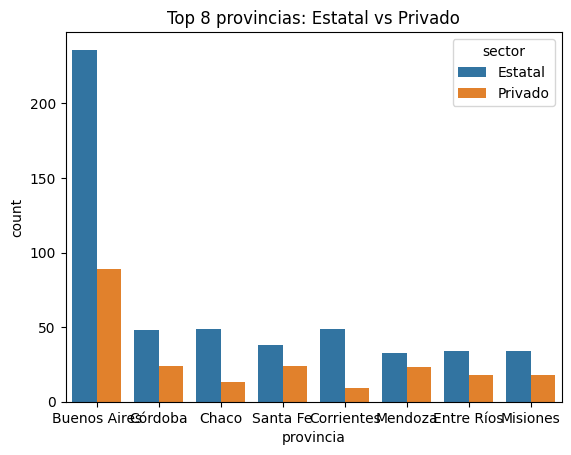

In [15]:
"""
Block 4989856b: 
- Defines variables: df; 
- Uses variables: df
"""

orden = df['provincia'].value_counts().head(8).index
df_top = df[df['provincia'].isin(orden)]

sns.countplot(data=df_top, x='provincia', hue='sector', order=orden)
plt.title('Top 8 provincias: Estatal vs Privado')
plt.show()

📌 Buenos Aires concentra la mayor matricula\. En las 8 provincias con más establecimientos predomina el sector estatal sobre el privado\.

## 3\. Observaciones generales

Se observa una concentración de la matrícula en Buenos Aires y una fuerte presencia estatal\. La calidad de los datos es buena, pero existen vacíos que corresponden a la falta de oferta de salas maternales en muchos jardines\. La variable más interesante es sector ya que muestra la desigualdad entre oferta estatal y privada\.

# 📁 Dataset 4 – Análisis de Ventas de Videojuegos \(Integrante: Brian Osorio\)

## 📝 Descripción del Dataset

El presente dataset contiene información sobre 172 videojuegos reales pertenecientes a diferentes géneros, como acción, aventura, RPG, terror, estrategia, simulación y supervivencia\.
El conjunto de datos comprende 4096 registros correspondientes a un escenario de ventas mensuales durante el período comprendido entre enero de 2024 y diciembre de 2025\.
Cada registro representa las ventas  de un videojuego durante un mes determinado, permitiendo analizar tanto las características individuales de cada título como su evolución comercial a lo largo del tiempo\.
La base de datos contiene 17 columnas, entre las que se incluyen el nombre del videojuego, género, año de lanzamiento, precio, presupuesto de desarrollo, presupuesto de marketing, calificación de usuarios, unidades vendidas e ingresos estimados\.
Los nombres de los videojuegos corresponden a títulos reales\. 
El objetivo principal del análisis exploratorio es investigar las relaciones entre las características de los videojuegos y su desempeño comercial, identificando posibles patrones que permitan desarrollar posteriormente modelos predictivos de inteligencia artificial\.

## Importación de Librerías

In [36]:
# ==========================================
# DATASET 4 - VIDEOJUEGOS
# IMPORTACIÓN DE LIBRERÍAS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de los gráficos
sns.set_theme(style="whitegrid")

# Mostrar todas las columnas del dataset
pd.set_option("display.max_columns", None)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 1\. Carga y exploración de datos

### Carga del dataset y exploración inicial

El primer paso consiste en importar el archivo CSV y visualizar la estructura general del conjunto de datos\.
Se busca verificar que la información haya sido cargada correctamente, conocer las variables disponibles e identificar la cantidad de filas y columnas presentes\.
Esta primera exploración también permite comprobar que el dataset cumple con los requisitos mínimos establecidos para el trabajo práctico\.

In [38]:
# ==========================================
# DATASET 4 - VIDEOJUEGOS
# CARGA Y EXPLORACIÓN INICIAL
# ==========================================

# Cargar el archivo CSV
df_videojuegos = pd.read_csv(
    "Dataset_Videojuegos_Ventas.csv"
)

# Mostrar los primeros registros
print("PRIMEROS 5 REGISTROS DEL DATASET")

display(df_videojuegos.head())

# Mostrar dimensiones
print("\nDIMENSIONES DEL DATASET")

print("Cantidad de filas:", df_videojuegos.shape[0])

print("Cantidad de columnas:", df_videojuegos.shape[1])

# Cantidad de videojuegos diferentes
print("\nCANTIDAD DE VIDEOJUEGOS DIFERENTES")

print(
    df_videojuegos["titulo"].nunique()
)

# Mostrar los nombres de todas las columnas
print("\nCOLUMNAS DISPONIBLES")

print(df_videojuegos.columns.tolist())

# Información general del dataset
print("\nINFORMACIÓN GENERAL DEL DATASET")

df_videojuegos.info()

# Verificar requisitos del trabajo práctico
print("\nVERIFICACIÓN DE REQUISITOS")

if df_videojuegos.shape[0] >= 2500:
    print("Cumple con el mínimo de 2500 filas.")
else:
    print("No cumple con el mínimo de filas.")

if df_videojuegos.shape[1] >= 9:
    print("Cumple con el mínimo de 9 columnas.")
else:
    print("No cumple con el mínimo de columnas.")

print("\nExploración inicial finalizada correctamente.")

PRIMEROS 5 REGISTROS DEL DATASET


,id_videojuego,titulo,anio_lanzamiento_original_aprox,mes_venta_simulado,genero_principal_referencial,escala_produccion_simulada,mercado_simulado,precio_lista_simulado_usd,descuento_simulado,precio_efectivo_simulado_usd,presupuesto_desarrollo_simulado_usd,presupuesto_marketing_simulado_usd,calificacion_usuarios_simulada,unidades_mes_simuladas,ventas_mes_millones_simuladas,ingresos_mes_simulados_usd,origen_datos
0,1,Grand Theft Auto V,2013,2024-01,Accion,AAA,PC (escenario simulado),79.99,0.0,79.99,23358466,30884844,99.0,31067,0.03107,2485049.33,Datos sinteticos; titulo real
1,1,Grand Theft Auto V,2013,2024-02,Accion,AAA,PC (escenario simulado),79.99,0.5,39.99,23358466,30884844,99.0,11494,0.01149,459645.06,Datos sinteticos; titulo real
2,1,Grand Theft Auto V,2013,2024-03,Accion,AAA,PC (escenario simulado),79.99,0.7,24.00,23358466,30884844,99.0,7436,0.00744,178464.00,Datos sinteticos; titulo real
3,1,Grand Theft Auto V,2013,2024-04,Accion,AAA,PC (escenario simulado),79.99,0.5,39.99,23358466,30884844,99.0,27983,0.02798,1119040.17,Datos sinteticos; titulo real
4,1,Grand Theft Auto V,2013,2024-05,Accion,AAA,PC (escenario simulado),79.99,0.1,71.99,23358466,30884844,99.0,12384,0.01238,891524.16,Datos sinteticos; titulo real



DIMENSIONES DEL DATASET
Cantidad de filas: 4096
Cantidad de columnas: 17

CANTIDAD DE VIDEOJUEGOS DIFERENTES
172

COLUMNAS DISPONIBLES
['id_videojuego', 'titulo', 'anio_lanzamiento_original_aprox', 'mes_venta_simulado', 'genero_principal_referencial', 'escala_produccion_simulada', 'mercado_simulado', 'precio_lista_simulado_usd', 'descuento_simulado', 'precio_efectivo_simulado_usd', 'presupuesto_desarrollo_simulado_usd', 'presupuesto_marketing_simulado_usd', 'calificacion_usuarios_simulada', 'unidades_mes_simuladas', 'ventas_mes_millones_simuladas', 'ingresos_mes_simulados_usd', 'origen_datos']

INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4096 entries, 0 to 4095
Data columns (total 17 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   id_videojuego                        4096 non-null   int64  
 1   titulo                               4096 non-null   ob

La exploración inicial permite verificar que el conjunto de datos contiene 4096 registros y 17 columnas, cumpliendo con los requisitos mínimos establecidos para el trabajo práctico\.
Se identifican 172 videojuegos diferentes, con registros mensuales correspondientes al período 2024\-2025\.
Las variables disponibles incluyen características categóricas, como el género y la escala de producción, y variables numéricas, como el precio, presupuesto de desarrollo, calificación de usuarios y unidades vendidas\.
Esta estructura permite realizar análisis estadísticos y estudiar posibles relaciones entre las características de los videojuegos y su rendimiento comercial\.

### Análisis estadístico y calidad de los datos

Una vez cargada la información, se realiza un análisis estadístico descriptivo para conocer las principales características del conjunto de datos\.
Se analizan medidas como el promedio, la mediana, los valores mínimos y máximos, y la desviación estándar de las variables numéricas\.
También se comprueba la existencia de valores faltantes y registros duplicados, con el objetivo de evaluar la calidad de los datos antes de realizar las visualizaciones\.
Debido a que cada videojuego puede aparecer en diferentes meses, también se analiza la cantidad de títulos únicos y su distribución por género\.

In [40]:
# Estadísticas descriptivas

print("ESTADÍSTICAS DESCRIPTIVAS")

display(df_videojuegos.describe())

# Valores faltantes

print("\nVALORES FALTANTES")

display(df_videojuegos.isnull().sum())

# Registros duplicados

print("\nREGISTROS DUPLICADOS")

print(df_videojuegos.duplicated().sum())

# Comprobar que no existan videojuegos repetidos
# dentro de un mismo mes

print("\nDUPLICADOS POR VIDEOJUEGO Y MES")

print(
    df_videojuegos.duplicated(
        subset=["id_videojuego", "mes_venta_simulado"]
    ).sum()
)

# Crear una tabla con un registro por videojuego

df_juegos_unicos = df_videojuegos.drop_duplicates(
    subset="id_videojuego"
)

# Cantidad de videojuegos por género

print("\nVIDEOJUEGOS POR GÉNERO")

display(
    df_juegos_unicos[
        "genero_principal_referencial"
    ].value_counts()
)

# Estadísticas de ventas

print("\nESTADÍSTICAS DE VENTAS MENSUALES")

print(
    "Promedio de unidades vendidas por registro:",
    round(
        df_videojuegos[
            "unidades_mes_simuladas"
        ].mean(),
        2
    )
)

print(
    "Mediana de unidades vendidas por registro:",
    df_videojuegos[
        "unidades_mes_simuladas"
    ].median()
)

print(
    "Máximo de unidades vendidas en un mes:",
    df_videojuegos[
        "unidades_mes_simuladas"
    ].max()
)

ESTADÍSTICAS DESCRIPTIVAS


,id_videojuego,anio_lanzamiento_original_aprox,precio_lista_simulado_usd,descuento_simulado,precio_efectivo_simulado_usd,presupuesto_desarrollo_simulado_usd,presupuesto_marketing_simulado_usd,calificacion_usuarios_simulada,unidades_mes_simuladas,ventas_mes_millones_simuladas,ingresos_mes_simulados_usd
count,4096.00000,4096.000000,4096.000000,4096.000000,4096.000000,4.096000e+03,4.096000e+03,4096.000000,4096.000000,4096.000000,4.096000e+03
mean,86.43750,2018.474609,38.031992,0.262402,27.961904,3.823752e+07,1.694811e+07,81.134082,10242.909180,0.010243,4.078230e+05
std,49.84136,3.400113,22.290658,0.230321,19.208650,4.277959e+07,2.506838e+07,8.759468,32019.192575,0.032019,1.580297e+06
min,1.00000,2010.000000,4.990000,0.000000,1.500000,4.514550e+05,1.229540e+05,59.500000,69.000000,0.000070,3.524900e+02
25%,43.00000,2016.000000,19.990000,0.000000,13.990000,2.330814e+06,1.170401e+06,75.300000,1296.750000,0.001300,1.946351e+04
50%,86.00000,2019.000000,29.990000,0.300000,23.990000,1.662370e+07,7.689629e+06,81.500000,3060.000000,0.003060,6.351882e+04
75%,130.00000,2021.000000,49.990000,0.500000,39.990000,7.037650e+07,2.437758e+07,87.100000,7619.750000,0.007620,2.304368e+05
max,172.00000,2024.000000,79.990000,0.700000,79.990000,2.098291e+08,1.500000e+08,99.000000,627851.000000,0.627850,3.283541e+07



VALORES FALTANTES


id_videojuego                          0
titulo                                 0
anio_lanzamiento_original_aprox        0
mes_venta_simulado                     0
genero_principal_referencial           0
escala_produccion_simulada             0
mercado_simulado                       0
precio_lista_simulado_usd              0
descuento_simulado                     0
precio_efectivo_simulado_usd           0
presupuesto_desarrollo_simulado_usd    0
presupuesto_marketing_simulado_usd     0
calificacion_usuarios_simulada         0
unidades_mes_simuladas                 0
ventas_mes_millones_simuladas          0
ingresos_mes_simulados_usd             0
origen_datos                           0
dtype: int64


REGISTROS DUPLICADOS
0

DUPLICADOS POR VIDEOJUEGO Y MES
0

VIDEOJUEGOS POR GÉNERO


genero_principal_referencial
Accion           39
RPG              27
Terror           22
Aventura         16
Supervivencia    16
Simulacion       13
Estrategia       13
Carreras          8
Puzzle            6
Deportes          6
Plataformas       5
Social            1
Name: count, dtype: int64


ESTADÍSTICAS DE VENTAS MENSUALES
Promedio de unidades vendidas por registro: 10242.91
Mediana de unidades vendidas por registro: 3060.0
Máximo de unidades vendidas en un mes: 627851


El análisis estadístico permite identificar diferencias importantes en el rendimiento comercial simulado de los videojuegos\.
El promedio de unidades vendidas por registro mensual es de aproximadamente 10\.243 copias, mientras que la mediana es de 3060 copias\.
Esta diferencia indica que la distribución de ventas presenta asimetría positiva: una cantidad reducida de registros con ventas elevadas incrementa el promedio general\.
También se observa que los géneros de acción, RPG y terror presentan una mayor cantidad de títulos dentro del conjunto de datos\.
En cuanto a la calidad de la información, no se identifican valores faltantes ni registros completamente duplicados\.
Es importante destacar que la presencia de un mismo videojuego en diferentes filas no representa un error, ya que cada registro corresponde a un mes distinto\.

## 2\. Visualizaciones y análisis

### Gráfico 1: Distribución de videojuegos por género

El primer gráfico tiene como objetivo analizar la distribución de los videojuegos según su género principal\.
Se utiliza un gráfico de barras para representar la cantidad de títulos pertenecientes a cada categoría\.
Para evitar contar varias veces un mismo videojuego, se considera únicamente un registro por título\.
Este análisis permite identificar qué géneros presentan mayor representación dentro del conjunto de datos\.

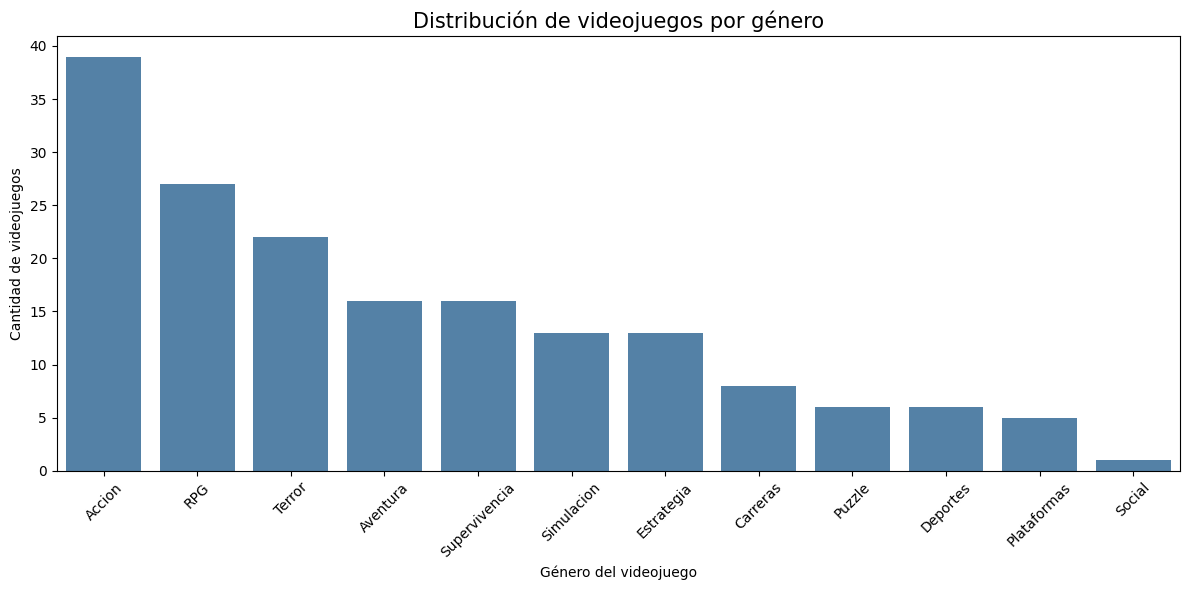

In [32]:
# GRÁFICO 1
# Distribución de videojuegos por género
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_videojuegos = pd.read_csv("Dataset_Videojuegos_Ventas.csv")

df_juegos_unicos = df_videojuegos.drop_duplicates(
    subset="id_videojuego"
)

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_juegos_unicos,
    x="genero_principal_referencial",
    order=df_juegos_unicos[
        "genero_principal_referencial"
    ].value_counts().index,
    color="steelblue"
)

plt.title(
    "Distribución de videojuegos por género",
    fontsize=15
)

plt.xlabel("Género del videojuego")

plt.ylabel("Cantidad de videojuegos")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

El gráfico muestra que el género de acción presenta la mayor cantidad de videojuegos dentro del conjunto de datos, con 39 títulos, seguido por RPG, con 27, y terror, con 22\.
También se identifican géneros como aventura, supervivencia, simulación, estrategia y carreras\.
La distribución evidencia una mayor representación de determinados géneros dentro de la muestra seleccionada\.
Sin embargo, esta diferencia no permite concluir que dichos géneros sean necesariamente los más vendidos, ya que la cantidad de videojuegos disponibles y el volumen de ventas constituyen variables distintas\.
Para investigar el rendimiento comercial resulta necesario incorporar información sobre las unidades vendidas y las características económicas de cada título\.

### Gráfico 2: Relación entre presupuesto de desarrollo y ventas

El segundo gráfico busca investigar la relación entre el presupuesto de desarrollo de los videojuegos y su rendimiento comercial durante el período analizado\.
Para ello, se utiliza un diagrama de dispersión que compara la inversión simulada de cada videojuego con la cantidad total de unidades vendidas durante 2024 y 2025\.
La información se agrupa por videojuego para evitar representar múltiples veces el mismo presupuesto de desarrollo\.
El objetivo es identificar posibles asociaciones entre el nivel de inversión y el volumen de ventas, así como observar diferencias entre videojuegos con características económicas similares\.

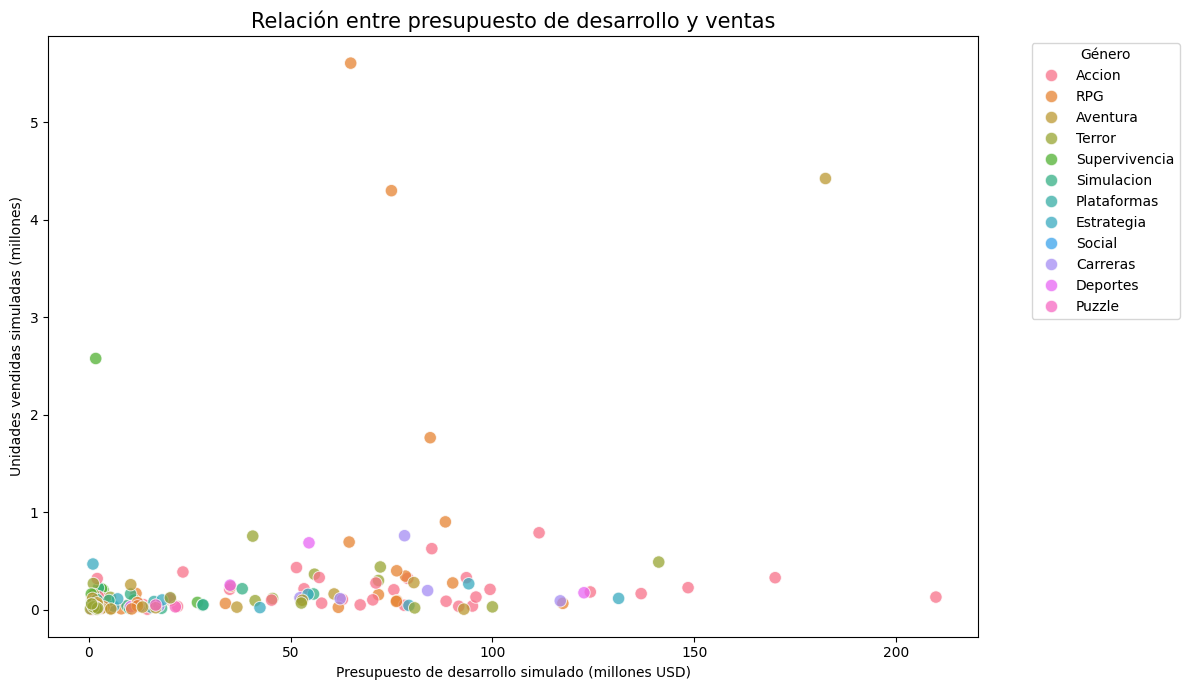

In [34]:
# GRÁFICO 2
# Relación entre presupuesto y ventas

# Agrupar las ventas mensuales por videojuego

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_videojuegos = pd.read_csv("Dataset_Videojuegos_Ventas.csv")
df_ventas_juego = df_videojuegos.groupby(
    [
        "id_videojuego",
        "titulo",
        "genero_principal_referencial"
    ],
    as_index=False
).agg(
    presupuesto_desarrollo=(
        "presupuesto_desarrollo_simulado_usd",
        "first"
    ),

    ventas_totales=(
        "unidades_mes_simuladas",
        "sum"
    )
)

# Convertir valores a millones

df_ventas_juego["presupuesto_millones"] = (
    df_ventas_juego["presupuesto_desarrollo"]
    / 1000000
)

df_ventas_juego["ventas_millones"] = (
    df_ventas_juego["ventas_totales"]
    / 1000000
)

# Crear gráfico

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_ventas_juego,
    x="presupuesto_millones",
    y="ventas_millones",
    hue="genero_principal_referencial",
    alpha=0.75,
    s=80
)

plt.title(
    "Relación entre presupuesto de desarrollo y ventas",
    fontsize=15
)

plt.xlabel(
    "Presupuesto de desarrollo simulado (millones USD)"
)

plt.ylabel(
    "Unidades vendidas simuladas (millones)"
)

plt.legend(
    title="Género",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

El gráfico permite observar una asociación positiva moderada entre el presupuesto de desarrollo y las ventas simuladas de los videojuegos\.
En términos generales, los títulos con mayores inversiones presentan una tendencia hacia volúmenes comerciales superiores\. Sin embargo, existe una dispersión importante entre videojuegos con presupuestos similares\.
También se identifican títulos con inversiones relativamente reducidas que alcanzan resultados comerciales elevados dentro del escenario simulado\.
Esto permite observar que el presupuesto de desarrollo no determina por sí solo el rendimiento comercial de un videojuego\.
Otras características, como el género, la recepción de los usuarios, el precio y la inversión en marketing, podrían contribuir a explicar las diferencias observadas\.
La relación identificada resulta interesante para un posible modelo predictivo orientado a estimar las ventas a partir de las características comerciales de los videojuegos\.

## 3\. Observaciones generales

El análisis exploratorio del dataset permitió identificar diferentes patrones relacionados con la distribución de los videojuegos y su rendimiento comercial simulado\.
En primer lugar, se observó que los géneros de acción, RPG y terror presentan una mayor representación dentro de la muestra, aunque esta distribución no implica necesariamente que sean los géneros con mayores ventas\.
En segundo lugar, se identificó una asociación positiva moderada entre el presupuesto de desarrollo y el volumen de ventas\. Los videojuegos con mayores inversiones tienden a presentar resultados comerciales superiores, aunque existen excepciones que evidencian que el presupuesto no constituye el único factor relacionado con el desempeño comercial\.
La distribución de las ventas presenta asimetría positiva, con una cantidad reducida de registros que alcanzan valores considerablemente superiores al resto\. Esta característica resulta relevante porque podría influir en el comportamiento de futuros modelos predictivos\.
En cuanto a la calidad de los datos, el conjunto presenta una estructura completa, sin valores faltantes ni registros duplicados\. Además, la organización mensual permite estudiar la evolución comercial de los videojuegos a lo largo del período analizado\.
Entre las variables más interesantes se destacan el presupuesto de desarrollo, el presupuesto de marketing, el género, el precio, las calificaciones de los usuarios y las unidades vendidas\.
Estas características permiten plantear futuras investigaciones relacionadas con los factores que podrían influir en el rendimiento comercial de los videojuegos\.
Como posible continuación del proyecto, se propone desarrollar un modelo de inteligencia artificial capaz de estimar el volumen de ventas de un videojuego a partir de sus características comerciales y técnicas\.
Finalmente, se destaca que las estadísticas económicas y comerciales utilizadas fueron generadas sintéticamente para fines académicos\. Por lo tanto, los patrones observados permiten estudiar un escenario simulado y no deben interpretarse como resultados históricos verificados del mercado real\.

In [24]:
df_delivery

,id_pedido,app_delivery,ciudad,tipo_cliente,tipo_comida,dia_semana,franja_horaria,distancia_km,monto_pedido,aplica_promocion,descuento_aplicado,costo_envio,tiempo_entrega_minutos,metodo_pago,estado_pedido,calificacion_orden
0,PED_00001,PedidosYa,CABA,Standard,Hamburguesas,Viernes,Almuerzo,3.9,22400.0,Sí,4400.0,4500,NaN,Tarjeta_Debito,Entregado,NaN
1,PED_00002,Zonakids,Mendoza,Standard,Helado,Viernes,Almuerzo,0.9,42700.0,Sí,10900.0,3500,20.0,Efectivo,Cancelado,5.0
2,PED_00003,Rappi,Mar del Plata,PRO,Sushi,Domingo,Almuerzo,2.3,85000.0,Sí,21600.0,500,43.0,Tarjeta_Credito,Entregado,5.0
3,PED_00004,Rappi,CABA,PRO,Empanadas,Viernes,Cena,4.9,55500.0,Sí,12300.0,0,46.0,Tarjeta_Debito,Entregado,4.0
4,PED_00005,pedidos ya,La Plata,Standard,Hamburguesas,Viernes,Cena,1.2,27500.0,No,0.0,3500,25.0,MercadoPago,Entregado,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3495,PED_03496,PedidosYa,Córdoba,Standard,Pizza,Sábado,Cena,5.5,27200.0,No,0.0,3500,44.0,Tarjeta_Credito,Entregado,NaN
3496,PED_03497,UberEats,rosario,Standard,Empanadas,Sábado,Tarde,1.4,15000.0,No,0.0,3500,47.0,Tarjeta_Credito,Entregado,5.0
3497,PED_03498,UberEats,La Plata,Standard,Árabe,Sábado,Madrugada,3.9,35100.0,No,0.0,3500,38.0,MercadoPago,Entregado,NaN
3498,PED_03499,PedidosYa,C.A.B.A.,Standard,Helado,Martes,Cena,3.9,99700.0,No,0.0,2500,38.0,Tarjeta_Credito,Entregado,5.0


# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

## 🏆 Dataset elegido: Delivery Market Argentina

## 📌 Motivos de la elección:

- El dataset presenta escenarios muy enriquecedores para la próxima etapa del proyecto, como la necesidad de imputar valores nulos\. Además, exige aplicar técnicas de limpieza y estandarización de texto para corregir inconsistencias de tipeo detectadas en variables categóricas clave como ciudad y app\_delivery\.

- Cuenta con 16 variables equlibradas que incluyen métricas financieras, hábitos de consumo y datos operativos \(como distancia\_km y tiempo\_entrega\_minutos\)\. Esto permite modelar problemáticas de gran utilidad, como predecir demoras, analizar sobrecostos o segmentar clientes según la franja horaria\.

- Durante el EDA, se identificaron potenciales valores atípicos, por ejemplo, distancias cercanas a los 60 km que elevan los tiempos de entrega hasta 180 minutos\. Trabajar con estos outliers resulta fundamental para entrenar modelos predictivos robustos\.

- Por último, este dataset nos ofrece un volumen de 3500 registros con un contexto local y un nivel de "suciedad" ideal para demostrar y aplicar integralmente los conocimientos de la materia en el ciclo completo de un sistema de Inteligencia Artificial\.

## 💡 Próximos pasos

- Limpieza y preparación del dataset elegido\.

- Diseño de una solución basada en la problemática detectada\.

- Implementación y validación del modelo\.

# SEGUNDA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Análisis EDA \(según lo trabajaron en la entrega 1\)
Análisis univariado, bivariado y/o multivariado
4 hipótesis sobre el dataset
Gráficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.

## 🔍 Introducción

Vamos a \.\.\.

# 📁 Dataset seleccionado– \[Nombre del dataset\] 

## 📝 Descripción del Dataset

Describir de que se trata el dataset

## Importación de Librerías

In [ ]:
#Importación de librerías

## 1\. Carga y exploración de datos

###  \[Nombre de la acción\]

Introducción a la acción

In [ ]:
# Código para cargar el dataset y mostrar estructura

Interpretación de la acción

###  \[Nombre de la acción\]

Introducción a la acción

In [ ]:
# Código para analizar el dataset y mostrar estructura

Interpretación de la acción

## 2\. Limpieza de Datos

## Analisis Univariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [ ]:
#Gráfico 1

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## 3\. Visualizaciones y análisis

## Analisis Univariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [ ]:
#Gráfico 1

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## Analisis Bivariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [ ]:
#Gráfico 1

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 2

In [ ]:
#Gráfico 2

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 3

In [ ]:
#Gráfico 3

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## Analisis Multivariado

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [ ]:
#Gráfico 1

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 2

In [ ]:
#Gráfico 2

📌 Interpretación del gráfico

###  \[Nombre del gráfico\]

Introducción al Gráfico 3

In [ ]:
#Gráfico 3

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

## 4\. Planteo de Hipótesis

###  \[Hipótesis 1\]

Introducción Hipótesis  

In [ ]:
#desarrollo Hipótesis 

In [ ]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 2\]

Introducción Hipótesis  

In [ ]:
#desarrollo Hipótesis 

In [ ]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 3\]

Introducción Hipótesis  

In [ ]:
#desarrollo Hipótesis 

In [ ]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

###  \[Hipótesis 4\]

Introducción Hipótesis  

In [ ]:
#desarrollo Hipótesis 

In [ ]:
#Grafico Hipótesis 

Explicación de lo que se desarrolló para ver si se cumple o no la hipótesis planteada

La Hipótesis se cumple o no se cumple

### \[Hipótesis 2\]

# ✅ Conclusión del equipo

Hemos podido observar que\.\.\.

# TERCERA ENTREGA

## 👉🏻 Consigna

Entregar por grupo un solo notebook trabajando sobre el dataset elegido por el equipo\. El notebook debe incluir lo siguiente:

Introducción y descripción del dataset
Planteamiento del objetivo del proyecto
Planteamiento de hipótesis y resumen de las conclusiones sobre las hipótesis
Análisis EDA
Análisis univariado
Análisis Bivariado y/o multivariado
Graficas orientadas a la respuesta de estas 4 hipótesis
Limpieza del dataset en caso de ser necesaria\.
Aplicación de modelos de Regresión,
Clasificación o Agrupación según lo planteado en el objetivo\.
\(mínimo 3 modelos\)
Métricas de evaluación del modelo aplicado
Selección del modelo más indicado en base a las métricas\.

## 🔍 Introducción 

# 📁 Dataset elegido – \[Nombre del dataset\] 

## 📝 Descripción del Dataset

Describir de que se trata el dataset

## Importación de Librerías

In [ ]:
#Importación de librerías

## 1\. Carga y exploración de datos

###  \[Nombre de la acción\]

Introducción a la acción

In [ ]:
# Código para cargar el dataset y mostrar estructura

Interpretación de la acción

###  \[Nombre de la acción\]

Introducción a la acción

In [ ]:
# Código para analizar el dataset y mostrar estructura

Interpretación de la acción

## 2\. Visualizaciones y análisis

###  \[Nombre del gráfico\]

Introducción al Gráfico 1

In [ ]:
#Gráfico 1

📌 Interpretación del gráfico

Introducción al Gráfico 2

In [ ]:
#Gráfico 2

📌 Interpretación del gráfico

Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?

# ✅ Conclusión del equipo

Después de analizar todos los datasets, el equipo ha decidido continuar el trabajo con el dataset:

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=211131b5-b140-4734-9e7a-3b26466af434' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>